In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load saved predictions
lstm = pd.read_csv(
    "Results/LSTM/lstm_predictions.csv"
)

adwin = pd.read_csv(
    "Results/LSTM_ADWIN/lstm_adwin_predictions.csv"
)

arima = pd.read_csv(
    "Results/ARIMA/arima_predictions.csv"
)

print("LSTM:", lstm.shape)
print("LSTM + ADWIN:", adwin.shape)
print("ARIMA:", arima.shape)

# Check whether evaluation records match
assert lstm["idx"].equals(adwin["idx"])
assert lstm["idx"].equals(arima["idx"])

assert np.allclose(lstm["actual"], adwin["actual"])
assert np.allclose(lstm["actual"], arima["actual"])

print("All three models use the same evaluation observations.")

LSTM: (595, 4)
LSTM + ADWIN: (595, 4)
ARIMA: (595, 4)
All three models use the same evaluation observations.


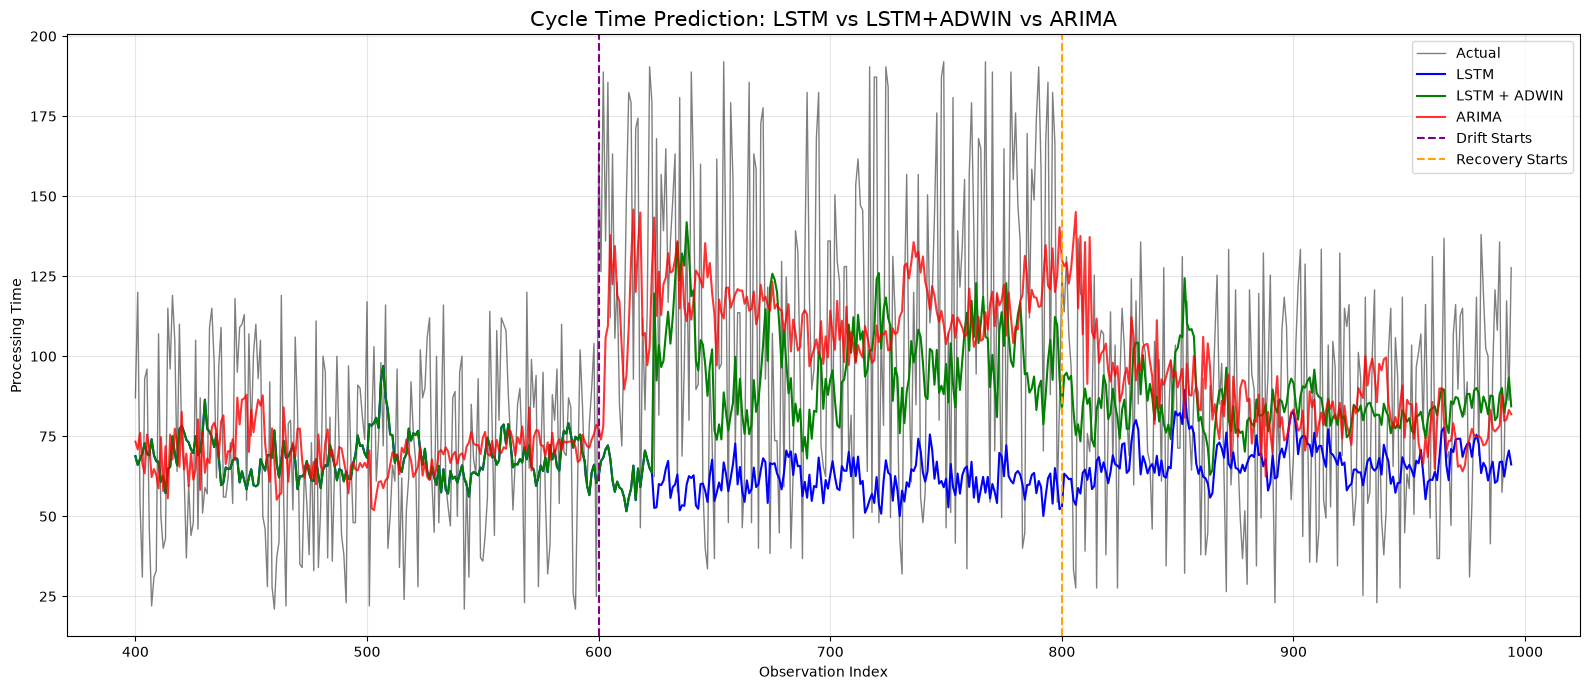

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create comparison results folder
OUTPUT_DIR = Path("Results/Comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_model_comparison(lstm, adwin, arima):

    fig, ax = plt.subplots(figsize=(16, 7))

    # Actual processing time
    ax.plot(
        lstm["idx"],
        lstm["actual"],
        label="Actual",
        color="black",
        linewidth=1,
        alpha=0.5
    )

    # Standalone LSTM
    ax.plot(
        lstm["idx"],
        lstm["predicted"],
        label="LSTM",
        color="blue",
        linewidth=1.5
    )

    # LSTM + ADWIN
    ax.plot(
        adwin["idx"],
        adwin["predicted"],
        label="LSTM + ADWIN",
        color="green",
        linewidth=1.5
    )

    # ARIMA
    ax.plot(
        arima["idx"],
        arima["predicted"],
        label="ARIMA",
        color="red",
        linewidth=1.5,
        alpha=0.8
    )

    # Operating phase boundaries
    ax.axvline(
        600,
        color="purple",
        linestyle="--",
        label="Drift Starts"
    )

    ax.axvline(
        800,
        color="orange",
        linestyle="--",
        label="Recovery Starts"
    )

    ax.set_title(
        "Cycle Time Prediction: LSTM vs LSTM+ADWIN vs ARIMA",
        fontsize=15
    )

    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Processing Time")

    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Save figure before displaying
    fig.savefig(
        OUTPUT_DIR / "all_models_actual_vs_predicted.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# Generate comparison graph
plot_model_comparison(lstm, adwin, arima)

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def evaluate_model(df, model_name):
    results = []

    for phase in ["stable", "drift", "recovery"]:
        subset = df[df["phase"] == phase]

        mae = mean_absolute_error(
            subset["actual"], subset["predicted"]
        )

        rmse = np.sqrt(mean_squared_error(
            subset["actual"], subset["predicted"]
        ))

        results.append({
            "Model": model_name,
            "Phase": phase,
            "MAE": mae,
            "RMSE": rmse
        })

    return pd.DataFrame(results)


comparison_df = pd.concat([
    evaluate_model(lstm, "LSTM"),
    evaluate_model(adwin, "LSTM + ADWIN"),
    evaluate_model(arima, "ARIMA")
], ignore_index=True)

display(comparison_df.round(2))

,Model,Phase,MAE,RMSE
0,LSTM,stable,24.28,28.44
1,LSTM,drift,61.13,74.04
2,LSTM,recovery,30.76,36.26
3,LSTM + ADWIN,stable,24.28,28.44
4,LSTM + ADWIN,drift,49.78,57.77
5,LSTM + ADWIN,recovery,27.88,32.54
6,ARIMA,stable,24.66,28.77
7,ARIMA,drift,44.21,50.85
8,ARIMA,recovery,28.87,35.35


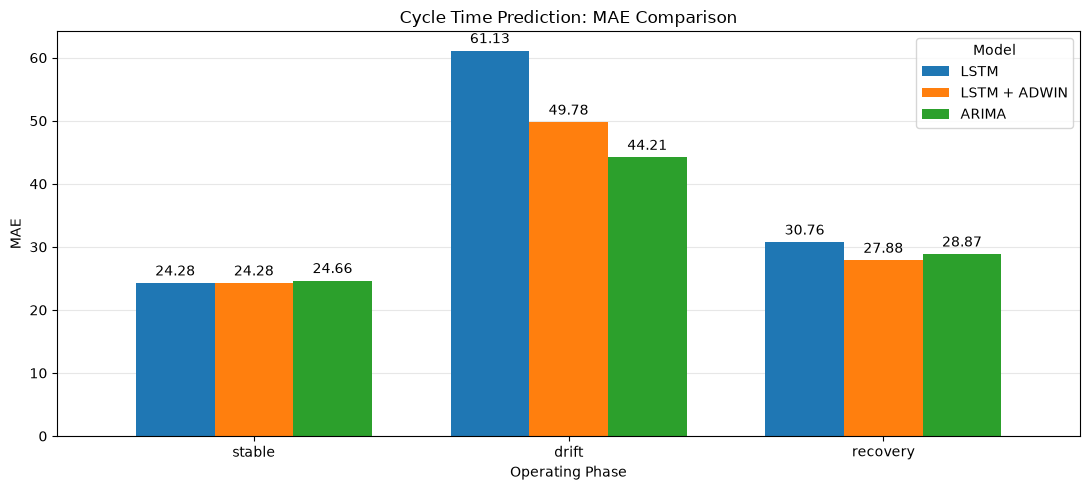

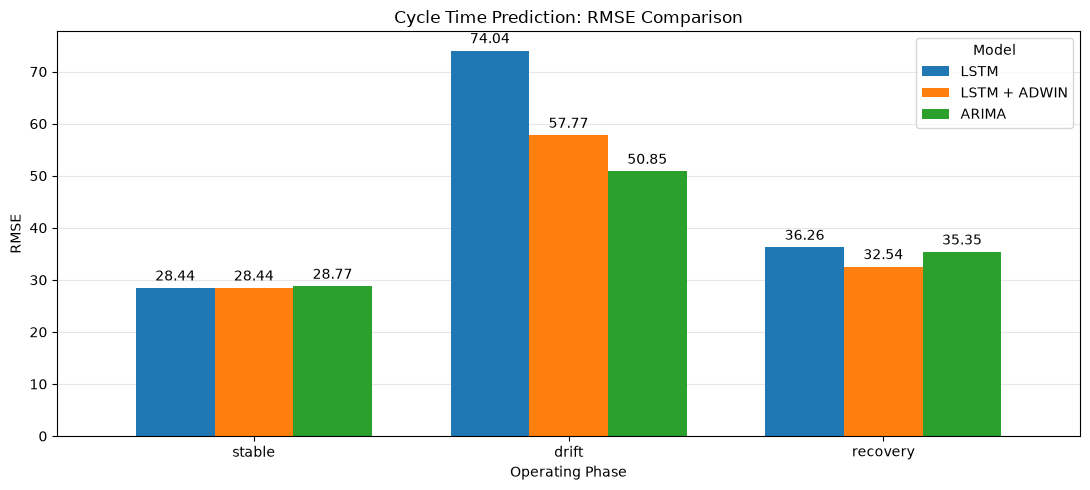

In [4]:
def plot_metric_comparison(comparison_df, metric):

    pivot = comparison_df.pivot(
        index="Phase",
        columns="Model",
        values=metric
    )

    pivot = pivot.loc[["stable", "drift", "recovery"]]
    pivot = pivot[["LSTM", "LSTM + ADWIN", "ARIMA"]]

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 5),
        width=0.75
    )

    ax.set_title(f"Cycle Time Prediction: {metric} Comparison")
    ax.set_xlabel("Operating Phase")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Model")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=3)

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    fig = ax.get_figure()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"model_comparison_{metric.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_metric_comparison(comparison_df, "MAE")
plot_metric_comparison(comparison_df, "RMSE")

In [5]:
comparison_df.to_csv(
    OUTPUT_DIR / "model_performance_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!
